# Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

## Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from pathlib import Path

WORKING_DIR = Path.cwd()
IMAGES_DIR = WORKING_DIR / "images"


def load_grayscale_matrix(path):
    img = Image.open(path).convert("L")
    imgmat = np.array(list(img.getdata(band=0)), float)
    imgmat.shape = (img.size[1], img.size[0])
    return np.matrix(imgmat)


def show_image(imgmat, title=None, figsize=(9, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(imgmat, cmap="gray")

    if title:
        plt.title(title)

    plt.show()


def compute_svd(imgmat):
    return np.linalg.svd(imgmat)


def reconstruct(U, sigma, V, start=0, stop=None, step=1):
    if stop is None:
        stop = len(sigma)
    return (
        np.matrix(U[:, start:stop:step])
        * np.diag(sigma[start:stop:step])
        * np.matrix(V[start:stop:step, :])
    )


def plot_singular_values(sigma, xlim=None):
    plt.figure()
    plt.plot(sigma)
    if xlim is not None:
        plt.xlim(0, xlim)
    plt.xlabel("index")
    plt.ylabel("singular value")
    plt.show()


def plot_ranges(U, sigma, V, ranges=None):
    if not ranges:
        return
        
    for j, i in ranges:
        reconstimg = reconstruct(U, sigma, V, start=j, stop=i)
        show_image(
            reconstimg,
            title=f"SVD reconstruction (j, i)=({j}, {i})"
        )


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

*If a non gray-scale version was used we would have another dimension to store each pixel color component value. In case of grayscale one number is perfectly sufficient to represent value of a single pixel, coloured picture though requires 3 numbers for each pixel. So grayscale image is a 2D matrix while color image is 3D tensor.*

In [61]:
imgmat = load_grayscale_matrix(IMAGES_DIR / "fields.jpeg")

/var/folders/d9/3r59pgz17qxdqxqpp6mkwn040000gn/T/ipykernel_21078/356400801.py:13: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  imgmat = np.array(list(img.getdata(band=0)), float)


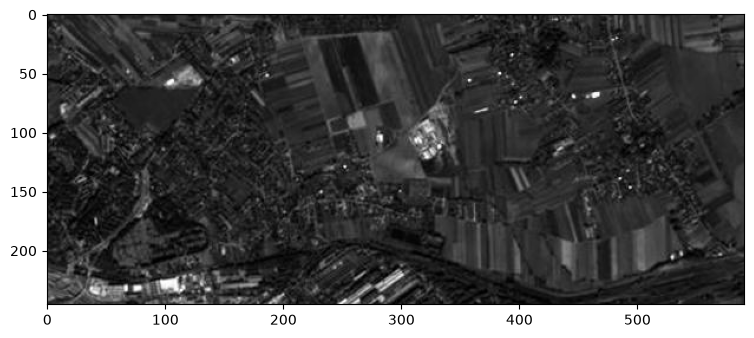

(246, 591)


In [62]:
show_image(imgmat)
print(imgmat.shape)

### SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

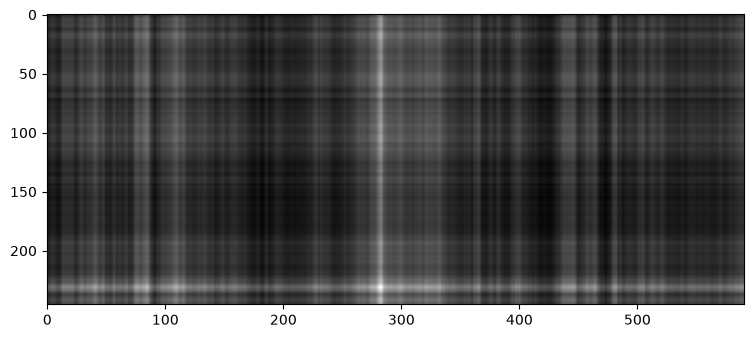

In [63]:
U, sigma, V = compute_svd(imgmat)
show_image(reconstruct(U, sigma, V, stop=1))


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

*In my opinion fairly good quallity appears while using ~75 vectors, we can see even more detailed and smaller, less noticeable structures.*

*If we omit the first vectors reconstructed image appears washed. It is happening because first few components with largest singular values encode the essential shapes and overall appearance of an image. The rest of eigen vectors is more detailed and subtle characteristics of an image. After removing first eigen vectors we are essentially building the image without its main characteristics, and without the most important components, thus the produced image appears "faint".*

(246, 246) (246,)


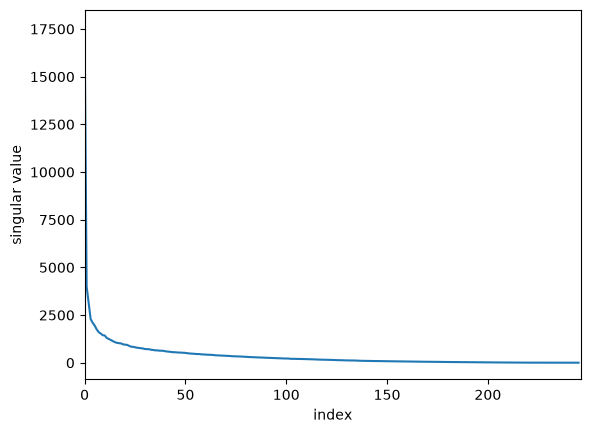

In [64]:
print(U.shape, sigma.shape)
plot_singular_values(sigma, xlim=imgmat.shape[0])

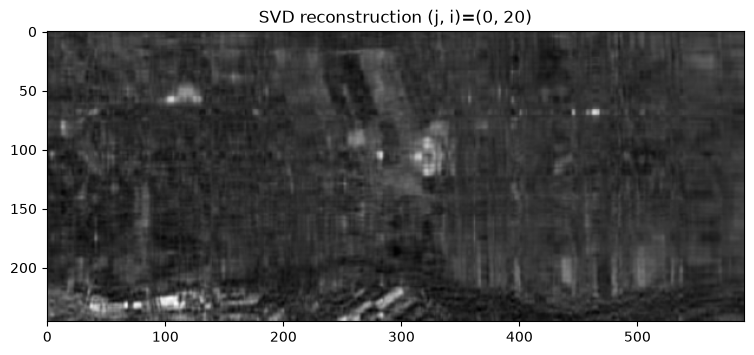

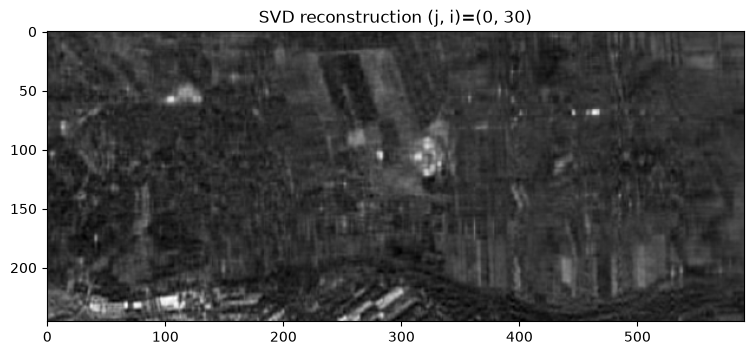

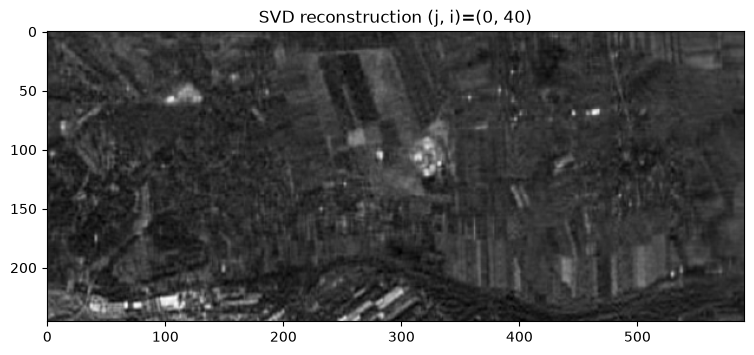

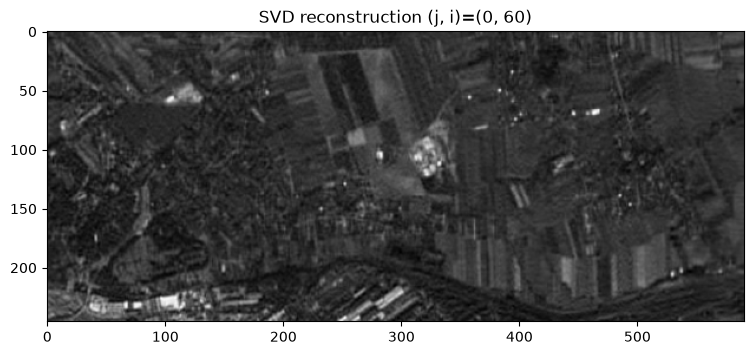

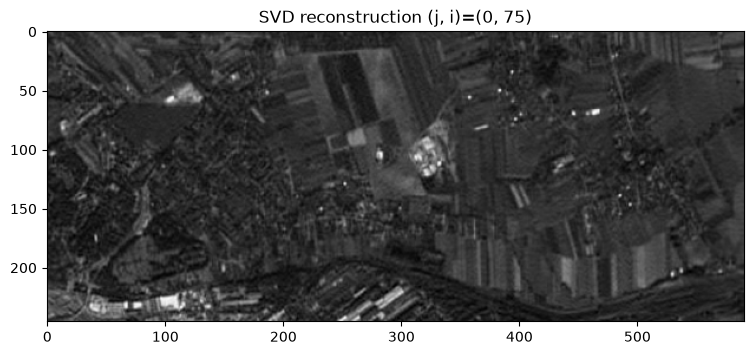

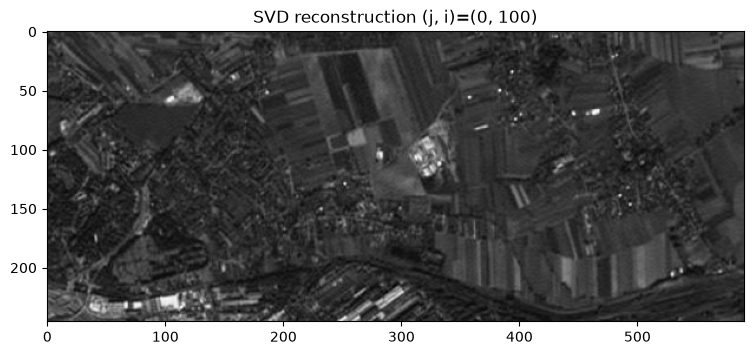

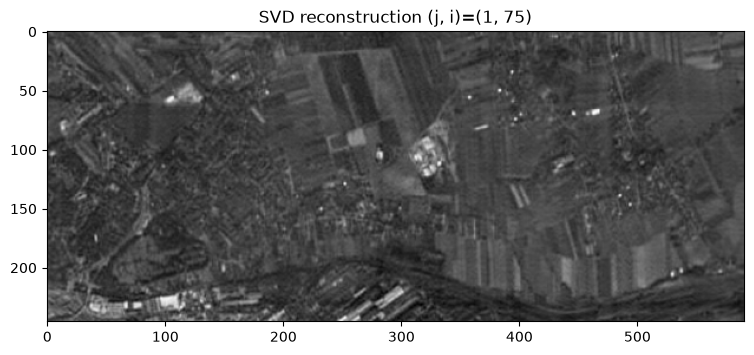

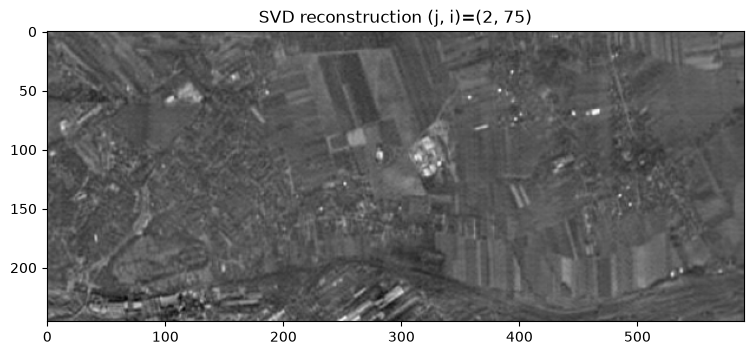

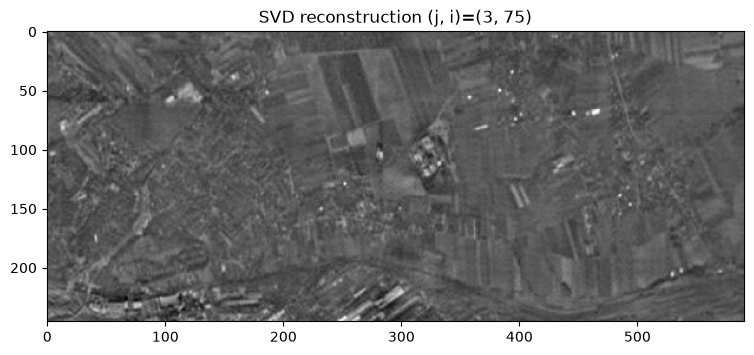

In [65]:
plot_ranges(
    U, sigma, V,
    ranges=[
        (0, 20), (0, 30), (0, 40), (0, 60), (0, 75), (0,100),
        (1, 75), (2, 75), (3, 75),
    ]
)

/var/folders/d9/3r59pgz17qxdqxqpp6mkwn040000gn/T/ipykernel_21078/3170778592.py:9: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  imgmat = np.array(list(img.getdata(band=0)), float)


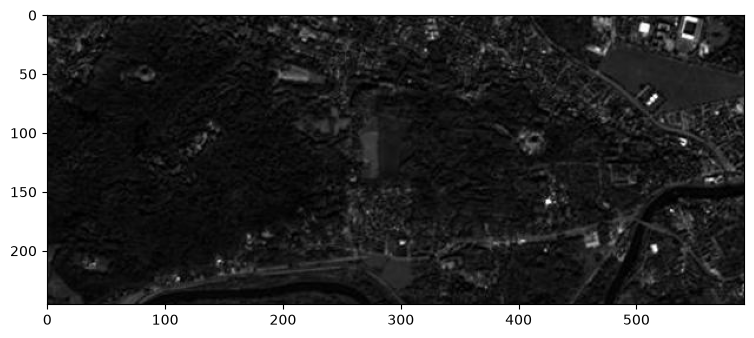

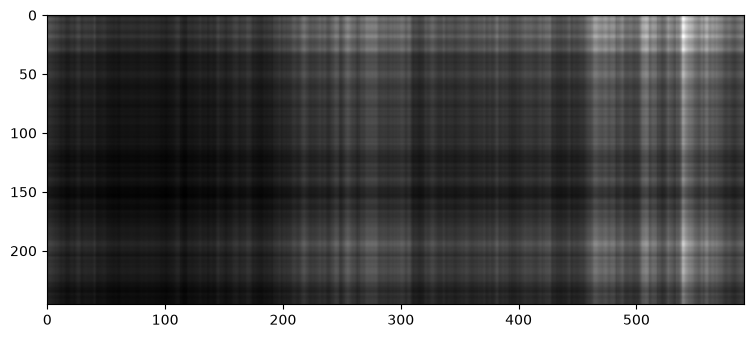

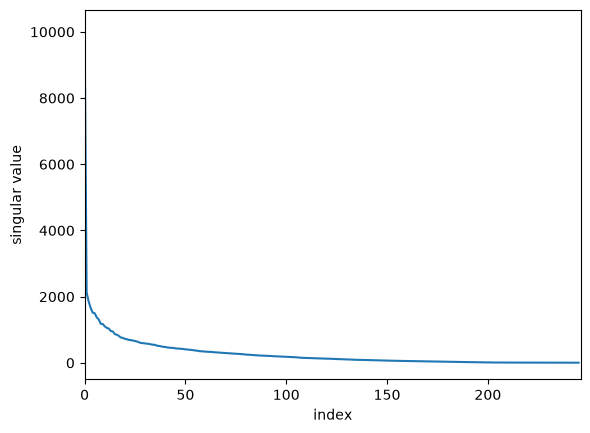

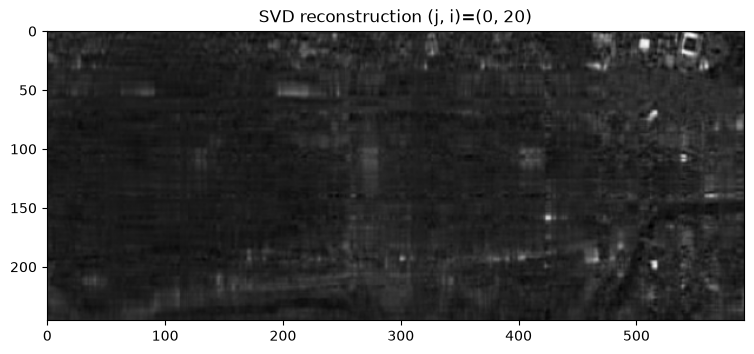

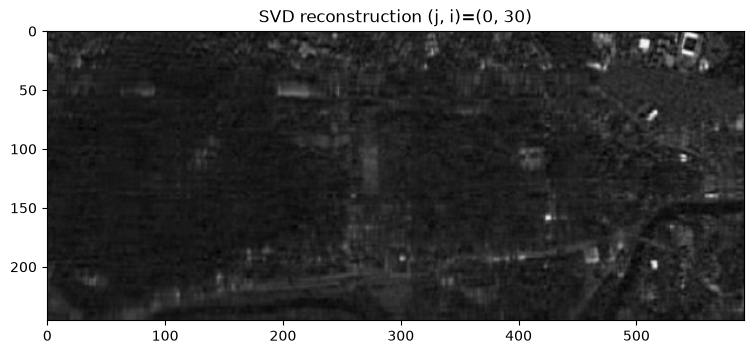

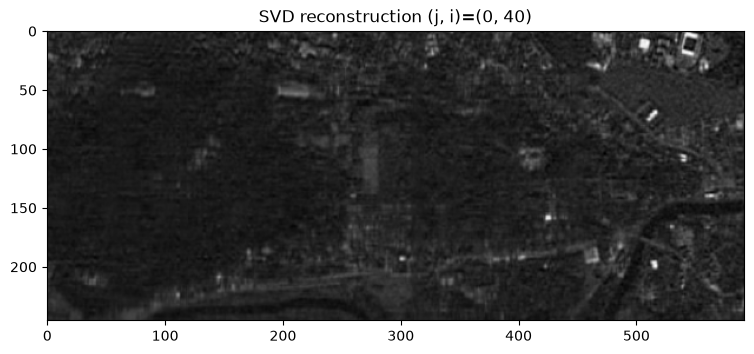

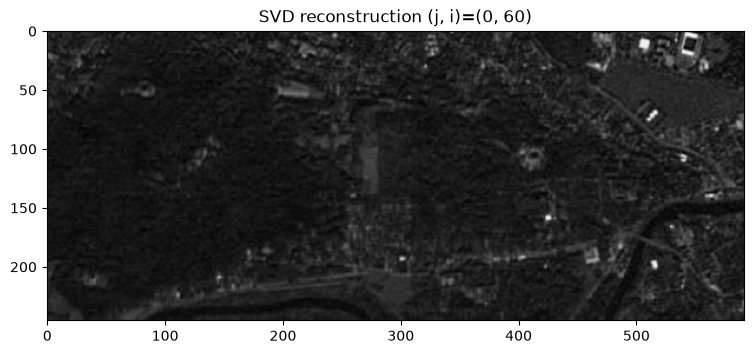

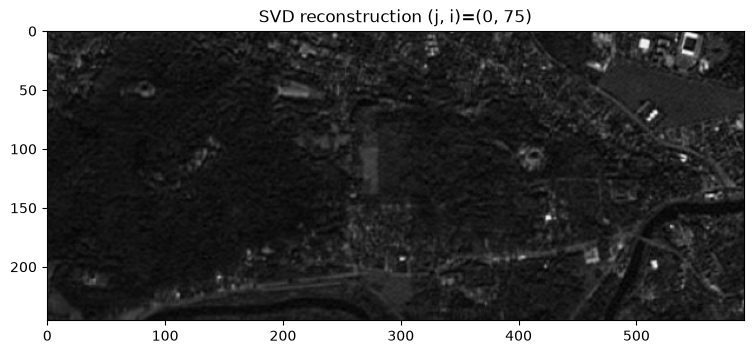

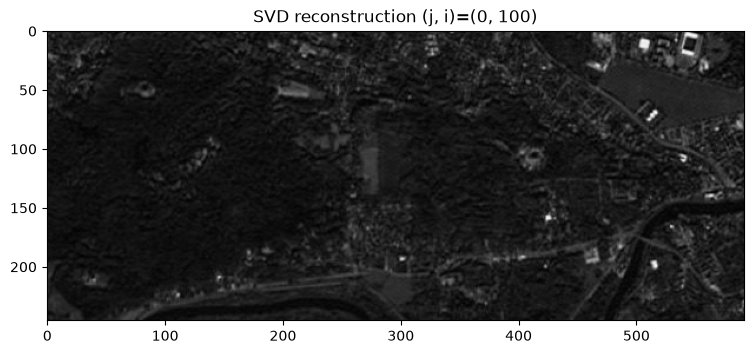

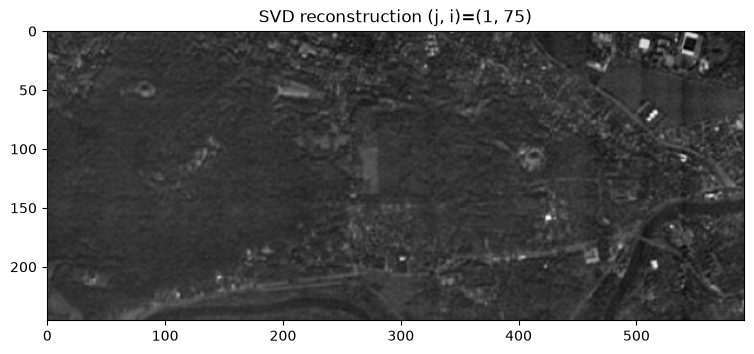

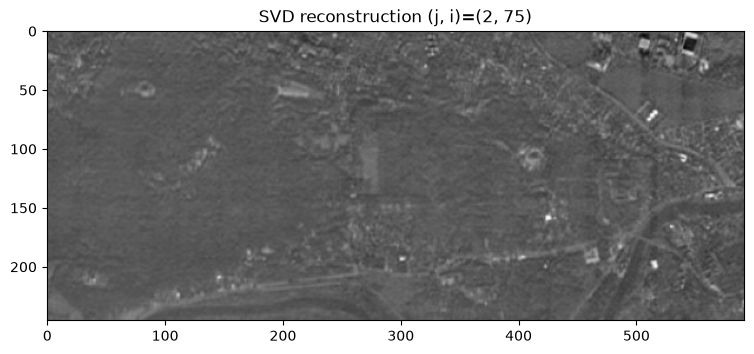

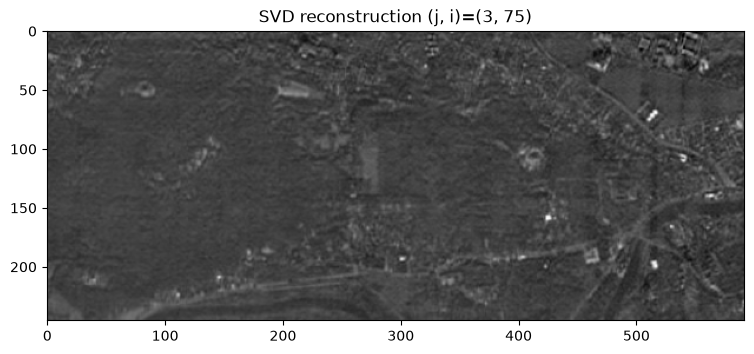

In [59]:
imgmat2 = load_grayscale_matrix(IMAGES_DIR / "forest_scene.jpeg")
show_image(imgmat2)
U2, sigma2, V2 = compute_svd(imgmat2)
show_image(reconstruct(U2, sigma2, V2, stop=1))
plot_singular_values(sigma2, xlim=imgmat2.shape[0])
plot_ranges(
    U2, sigma2, V2,
    ranges=[
        (0, 20), (0, 30), (0, 40), (0, 60), (0, 75), (0, 100),
        (1, 75), (2, 75), (3, 75),
    ]
)